# 01 · Exploratory Data Analysis — NASA Milling Tool Wear

**Dataset:** Goebel & Agogino, NASA Ames Prognostics Data Repository (`data/raw/mill.mat`, docs in `docs/dataset_readme.pdf`).

167 milling runs across 16 *cases* (one insert each, run until worn). Every run records six sensor channels
at 250 Hz for 36 s, and the flank wear **VB (mm)** was measured after *some* runs.

**Questions for this notebook**
1. What is in the data, and how clean is it?
2. How does wear progress, and how much do process settings (material, depth of cut, feed) matter?
3. Which parts of each signal are usable, and which signal features track wear?

Prerequisite: `python scripts/make_dataset.py`

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().resolve().parent if Path.cwd().name == "notebooks" else Path.cwd().resolve()
sys.path.insert(0, str(ROOT / "src"))

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.lines import Line2D
from scipy import signal as sps

from milling.data import FS, SIGNALS, SMC_DC_SATURATION
from milling.utils import INK_MUTED, MATERIAL_COLORS, PALETTE, load_config, set_plot_style

set_plot_style()
pd.set_option("display.precision", 3)
cfg = load_config(ROOT / "configs/baseline.yaml")
WINDOW = tuple(cfg["features"]["window"])
FIG_DIR = ROOT / "reports/figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)


def save(fig, name):
    fig.savefig(FIG_DIR / f"eda_{name}.png")


PROC = ROOT / "data/processed"
runs = pd.read_csv(PROC / "runs.csv")
signals = np.load(PROC / "signals.npy")
features = pd.read_csv(PROC / "features.csv")
t_axis = np.arange(signals.shape[-1]) / FS
print(f"runs {runs.shape}, signals {signals.shape}, features {features.shape}")

runs (167, 14), signals (167, 6, 9000), features (167, 104)


## 1. Overview of the experimental design
A full 2×2×2 factorial (material × depth of cut × feed), each setting repeated with a second insert → 16 cases.
Duplicate pairs: (1, 9), (2, 12), (3, 11), (4, 10), (5, 16), (6, 15), (7, 13), (8, 14).

In [2]:
overview = (
    runs.groupby("case")
    .agg(
        material=("material_name", "first"),
        DOC=("DOC", "first"),
        feed=("feed", "first"),
        n_runs=("run", "size"),
        n_valid=("valid", "sum"),
        n_VB=("vb_measured", "sum"),
        max_time_min=("time", "max"),
        final_VB=("VB", lambda s: s.dropna().iloc[-1] if s.notna().any() else np.nan),
    )
    .reset_index()
)
overview

,case,material,DOC,feed,n_runs,n_valid,n_VB,max_time_min,final_VB
0,1,cast_iron,1.50,0.50,17,17,13,48.0,0.44
1,2,cast_iron,0.75,0.50,14,13,13,72.0,0.55
2,3,cast_iron,0.75,0.25,14,14,14,81.0,0.55
3,4,cast_iron,1.50,0.25,7,7,7,39.0,0.49
4,5,steel,1.50,0.50,6,6,6,15.0,0.74
5,6,steel,1.50,0.25,1,1,1,0.0,0.00
6,7,steel,0.75,0.25,8,8,7,21.0,0.46
7,8,steel,0.75,0.50,6,6,5,12.0,0.62
8,9,cast_iron,1.50,0.50,9,9,9,46.0,0.81
9,10,cast_iron,1.50,0.25,10,10,10,57.0,0.70


In [3]:
print("Total runs:", len(runs), "| valid:", runs.valid.sum(), "| with measured VB:", runs.vb_measured.sum(),
      "| usable labelled (valid & VB):", (runs.valid & runs.vb_measured).sum())
print("Runs per material:", runs.material_name.value_counts().to_dict())
print(runs[["time", "VB"]].describe().T)

Total runs: 167 | valid: 165 | with measured VB: 146 | usable labelled (valid & VB): 145
Runs per material: {'cast_iron': 109, 'steel': 58}
      count    mean     std  min   25%     50%     75%     max
time  167.0  26.114  23.293  0.0  7.50  19.000  39.000  105.00
VB    146.0   0.338   0.261  0.0  0.15   0.285   0.467    1.53


## 2. Data quality
* **Corrupted records** — flagged in `make_dataset.py`.
* **Missing labels** — VB was not measured after every run.
* **Clipping** — the spindle-motor DC current saturates at the ADC ceiling (≈9.995 V) under heavy load.

In [4]:
runs.loc[~runs.valid, ["case", "run", "VB", "invalid_reason"]]

,case,run,VB,invalid_reason
17,2,1,0.08,non-physical values (overflow)
115,12,1,NaN,length [15360] != 9000


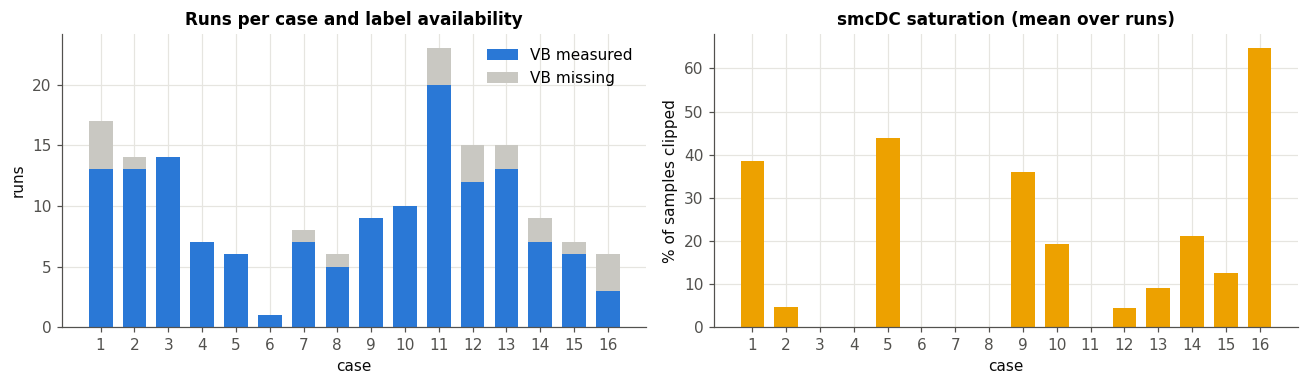

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 3.6))
ov = overview.set_index("case")
axes[0].bar(ov.index, ov.n_VB, color=PALETTE[0], label="VB measured", width=0.7)
axes[0].bar(ov.index, ov.n_runs - ov.n_VB, bottom=ov.n_VB, color="#c9c8c2", label="VB missing", width=0.7)
axes[0].set(xlabel="case", ylabel="runs", title="Runs per case and label availability", xticks=ov.index)
axes[0].legend()

sat = runs.pivot_table(index="case", values="smcDC_saturation", aggfunc="mean")
axes[1].bar(sat.index, 100 * sat.smcDC_saturation, color=PALETTE[3], width=0.7)
axes[1].set(xlabel="case", ylabel="% of samples clipped", title="smcDC saturation (mean over runs)", xticks=ov.index)
fig.tight_layout(); save(fig, "data_quality")

Case 6 has a **single run** (VB = 0) — it carries no wear-progression information.
Heavy-cut cases saturate smcDC for a large share of the run, so its amplitude features are capped there.

## 3. How does wear progress?

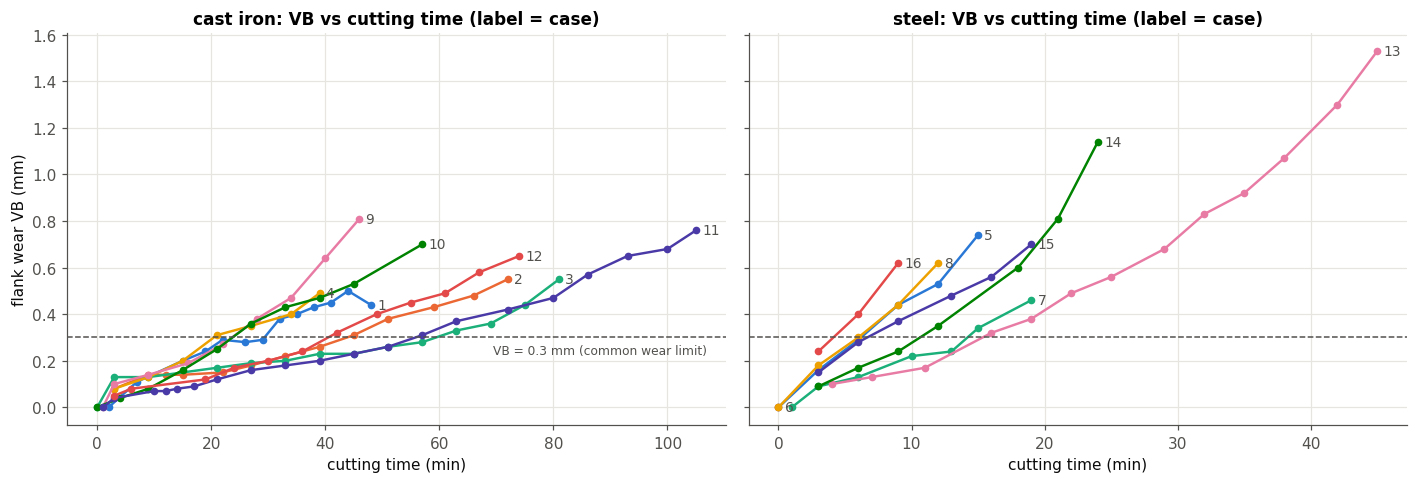

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, mat in zip(axes, ["cast_iron", "steel"]):
    sub = runs[(runs.material_name == mat) & runs.vb_measured]
    for k, (case, g) in enumerate(sub.groupby("case")):
        c = PALETTE[k % len(PALETTE)]
        ax.plot(g.time, g.VB, "-o", color=c, ms=4, lw=1.6)
        ax.annotate(f"{case}", (g.time.iloc[-1], g.VB.iloc[-1]), xytext=(4, 0), textcoords="offset points",
                    fontsize=9, color=INK_MUTED, va="center")
    ax.axhline(0.3, ls="--", color=INK_MUTED, lw=1)
    ax.set(title=f"{mat.replace('_', ' ')}: VB vs cutting time (label = case)", xlabel="cutting time (min)")
axes[0].set_ylabel("flank wear VB (mm)")
axes[0].text(107, 0.27, "VB = 0.3 mm (common wear limit)", fontsize=8, color=INK_MUTED, va="top", ha="right")
fig.tight_layout(); save(fig, "wear_curves")

Wear is **monotonic and accelerating** (classic run-in → steady → rapid-wear shape), and steel wears
far faster than cast iron: steel inserts reach 0.3 mm after ~4–15 min vs ~20–60 min for cast iron.
(Case 1 shows a small VB *decrease* near the end — measurement noise on a microscope reading.)

In [7]:
def time_to(vb_limit, g):
    g = g.dropna(subset=["VB"])
    if g.VB.max() < vb_limit:
        return np.nan
    return float(np.interp(vb_limit, g.VB.cummax(), g.time))


life = (
    runs[runs.vb_measured]
    .groupby("case")
    .apply(lambda g: pd.Series({
        "material": g.material_name.iloc[0], "DOC": g.DOC.iloc[0], "feed": g.feed.iloc[0],
        "wear_rate_mm_per_min": np.polyfit(g.time, g.VB, 1)[0] if len(g) > 2 else np.nan,
        "time_to_0.3mm": time_to(0.3, g),
    }))
    .reset_index()
)
life

,case,material,DOC,feed,wear_rate_mm_per_min,time_to_0.3mm
0,1,cast_iron,1.50,0.50,0.010,29.333
1,2,cast_iron,0.75,0.50,0.007,43.800
2,3,cast_iron,0.75,0.25,0.005,59.400
3,4,cast_iron,1.50,0.25,0.011,20.455
4,5,steel,1.50,0.50,0.047,6.200
5,6,steel,1.50,0.25,NaN,NaN
6,7,steel,0.75,0.25,0.023,14.200
7,8,steel,0.75,0.50,0.050,6.000
8,9,cast_iron,1.50,0.50,0.016,23.636
9,10,cast_iron,1.50,0.25,0.012,23.727


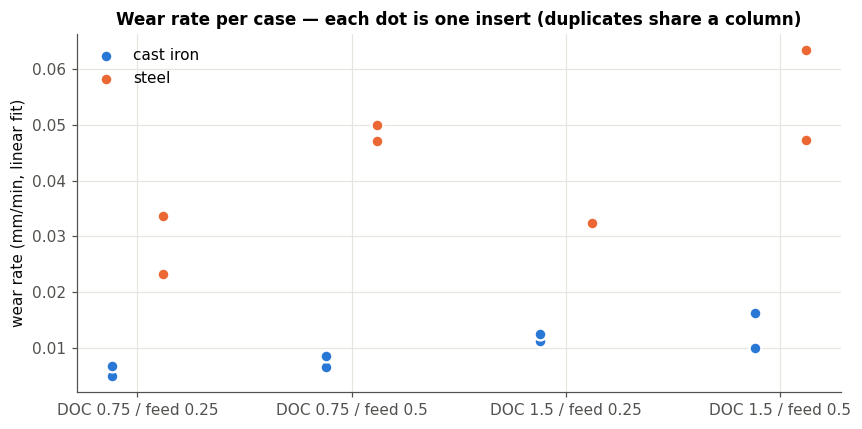

In [8]:
fig, ax = plt.subplots(figsize=(8, 4))
life["setting"] = life.apply(lambda r: f"DOC {r.DOC} / feed {r.feed}", axis=1)
settings = sorted(life.setting.unique())
for mat, off in [("cast_iron", -0.12), ("steel", 0.12)]:
    s = life[life.material == mat]
    x = [settings.index(v) + off for v in s.setting]
    ax.scatter(x, s.wear_rate_mm_per_min, s=60, color=MATERIAL_COLORS[mat], label=mat.replace("_", " "),
               edgecolor="white", linewidth=1.5, zorder=3)
ax.set_xticks(range(len(settings)), settings)
ax.set(ylabel="wear rate (mm/min, linear fit)", title="Wear rate per case — each dot is one insert (duplicates share a column)")
ax.legend(); fig.tight_layout(); save(fig, "wear_rate")

* **Material dominates** the wear rate; depth of cut and feed matter less and not consistently.
* **Duplicates disagree** — the two inserts at identical settings can differ by 2× in wear rate. This
  is the insert-to-insert variability the dataset readme warns about, and the main reason a
  model must be validated on *unseen inserts* (leave-one-case-out), not random runs.

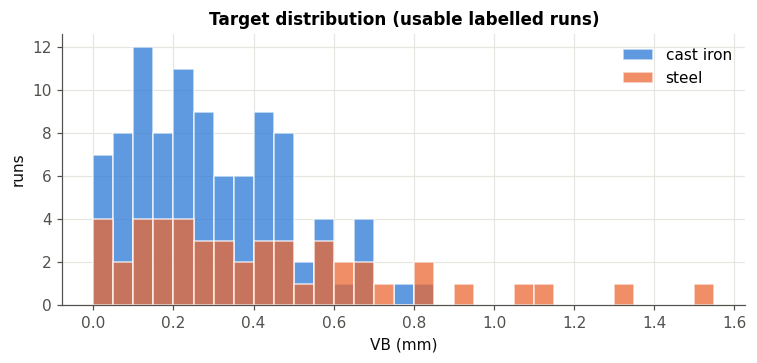

In [9]:
fig, ax = plt.subplots(figsize=(7, 3.4))
lab = runs[runs.valid & runs.vb_measured]
bins = np.arange(0, 1.6, 0.05)
for mat in ["cast_iron", "steel"]:
    ax.hist(lab[lab.material_name == mat].VB, bins=bins, color=MATERIAL_COLORS[mat], alpha=0.75,
            label=mat.replace("_", " "), edgecolor="white")
ax.set(xlabel="VB (mm)", ylabel="runs", title="Target distribution (usable labelled runs)")
ax.legend(); fig.tight_layout(); save(fig, "vb_hist")

The target is right-skewed; only case 13 and 14 (steel) push beyond 1 mm, so the high-wear tail is sparse.

## 4. Signal anatomy — where is the steady-state cut?
Each 36 s record contains idle → **entry** → steady cut → **exit** → idle. Entry/exit transients are
dominated by engagement geometry, not wear, so features are computed on the shaded window.

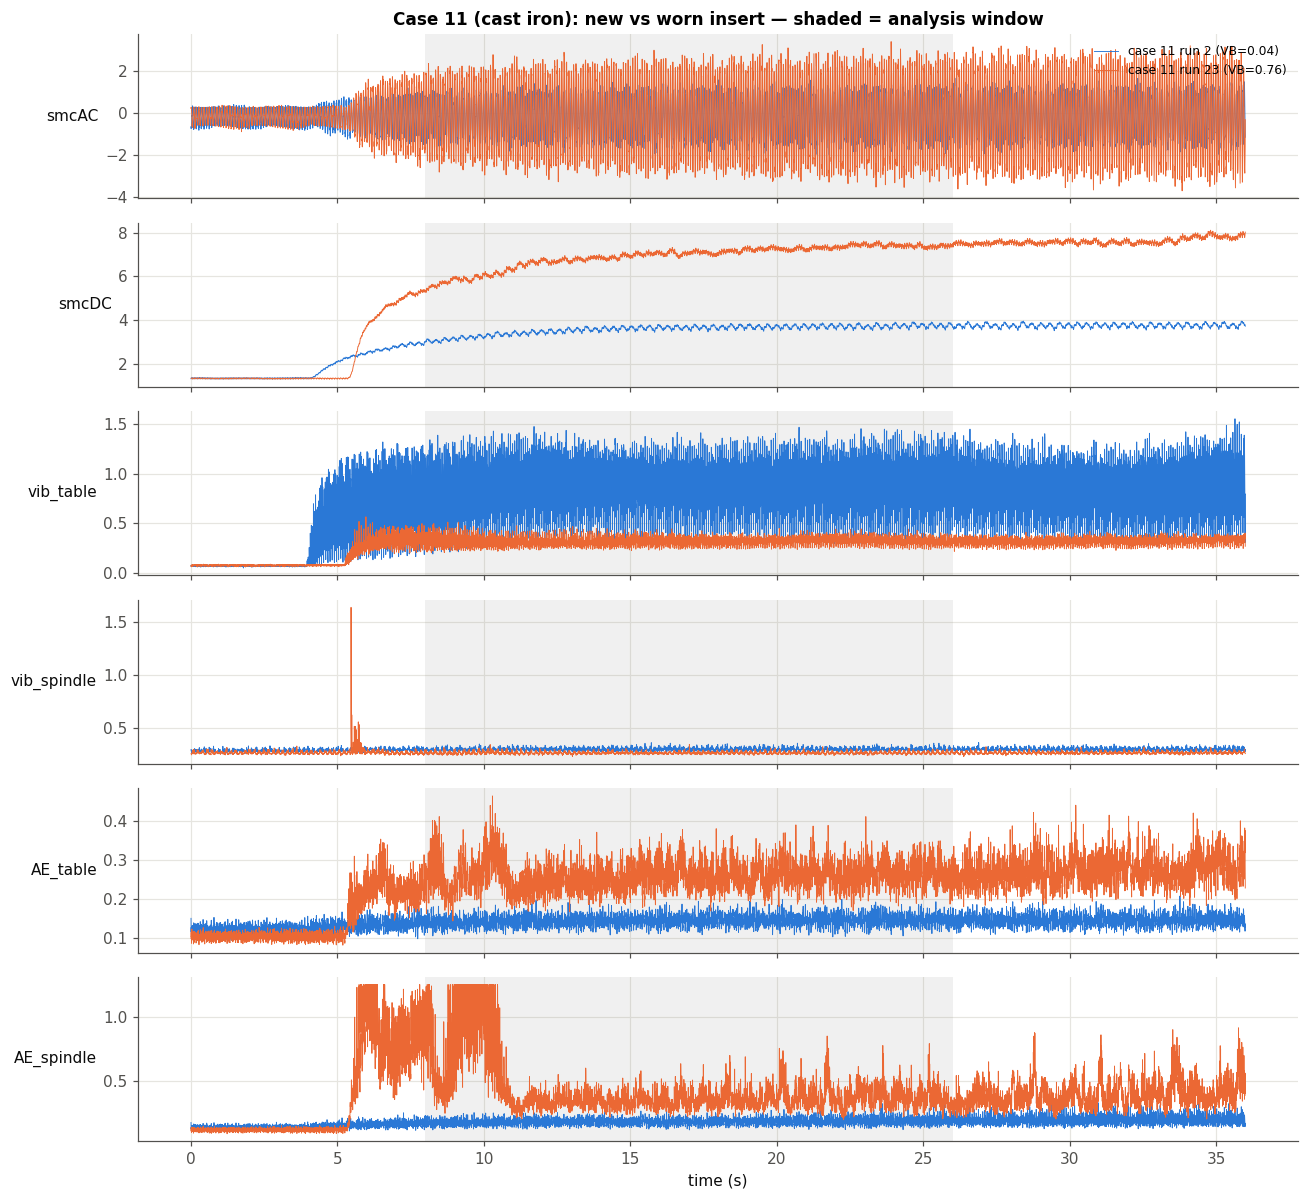

In [10]:
def plot_run(idx_list, title, name):
    fig, axes = plt.subplots(len(SIGNALS), 1, figsize=(12, 11), sharex=True)
    for k, i in enumerate(idx_list):
        r = runs.iloc[i]
        for ax, ch, name_ in zip(axes, range(len(SIGNALS)), SIGNALS):
            ax.plot(t_axis, signals[i, ch], lw=0.6, color=PALETTE[k],
                    label=f"case {r.case} run {r.run} (VB={r.VB if pd.notna(r.VB) else 'n/a'})")
            ax.set_ylabel(name_, rotation=0, ha="right", va="center")
    for ax in axes:
        ax.axvspan(WINDOW[0] / FS, WINDOW[1] / FS, color="#8a8984", alpha=0.12, lw=0)
    axes[0].legend(loc="upper right", fontsize=8)
    axes[0].set_title(title)
    axes[-1].set_xlabel("time (s)")
    fig.tight_layout(); save(fig, name)


pick = lambda c, r: runs.index[(runs.case == c) & (runs.run == r)][0]
plot_run([pick(11, 2), pick(11, 23)], "Case 11 (cast iron): new vs worn insert — shaded = analysis window", "signals_case11")

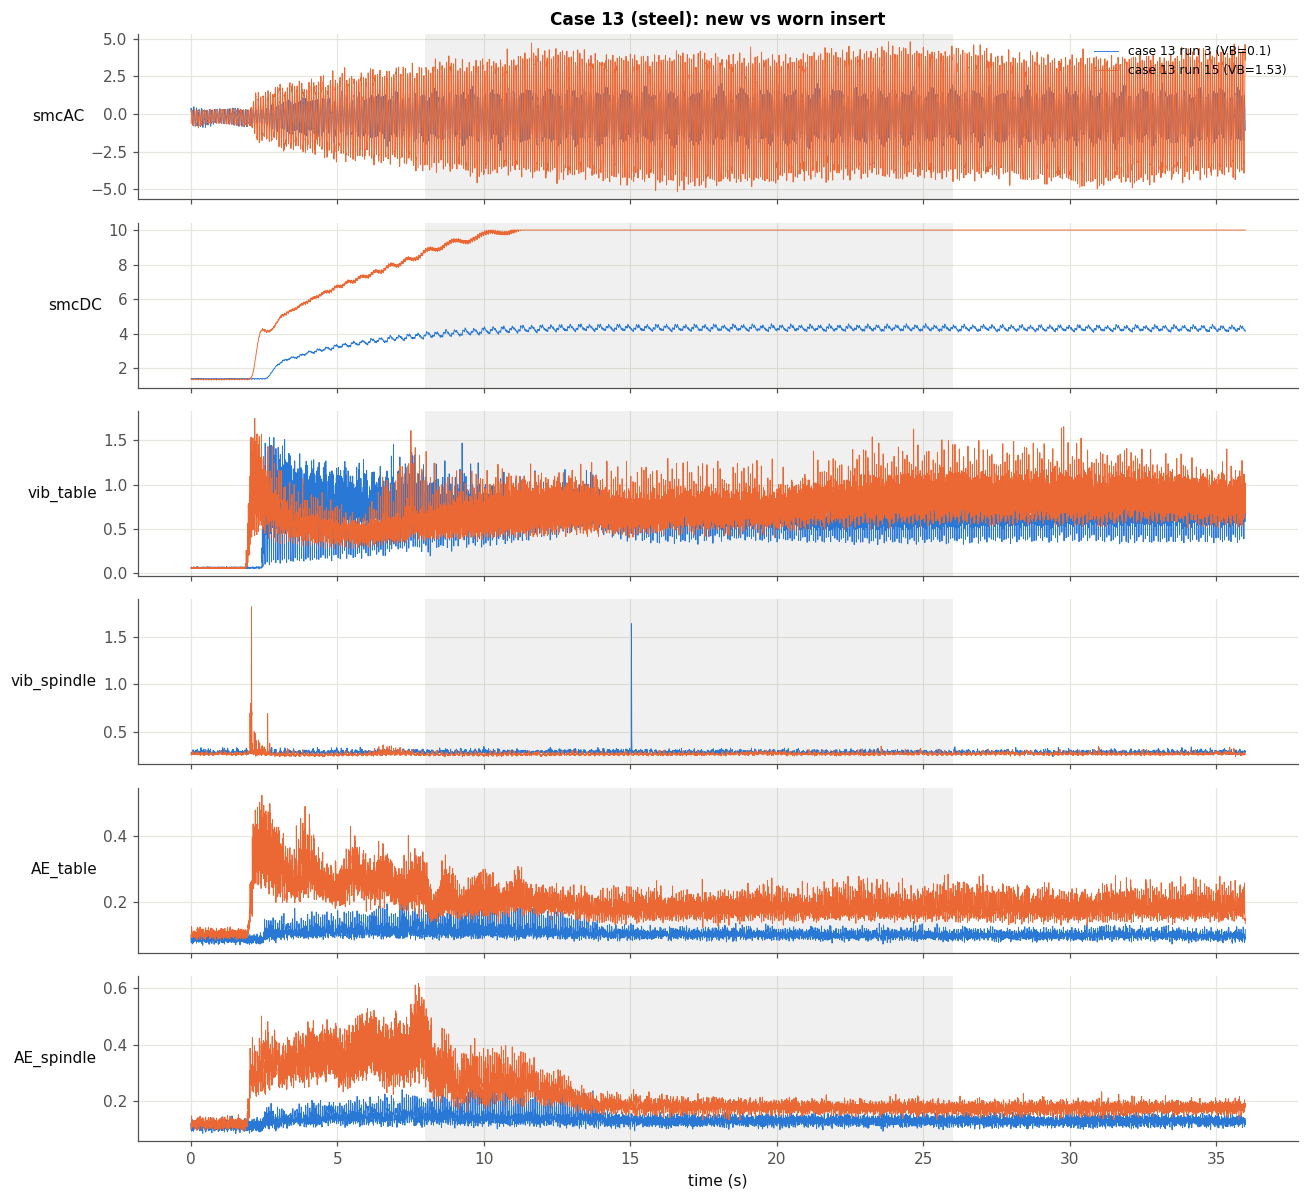

In [11]:
plot_run([pick(13, 3), pick(13, 15)], "Case 13 (steel): new vs worn insert", "signals_case13")

### One run, all six channels (slide figure)
The six synchronized signals of a single run (case 2, run 3: cast iron, VB = 0.14 mm), stacked on a shared
time axis. Every channel shows the full cycle: idle → tool enters (~3 s) → steady cut → tool exits (~28 s) → idle.
Each channel is scaled to its own 1st–99th percentile range **within the run** so all six fit one panel,
which means amplitudes can't be compared *between* channels. Exported as a 300 dpi PNG and an SVG
(`reports/figures/slide_sensor_channels.*`) for slides.

case 2 run 3: cast_iron, DOC 0.75, feed 0.5, VB 0.14 mm, 9000 samples @ 250 Hz = 36 s


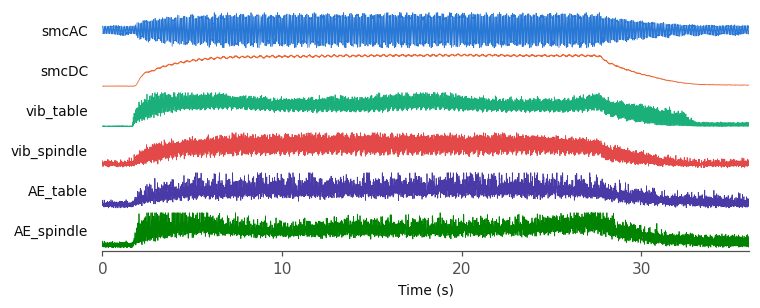

In [12]:
SLIDE_RUN = (2, 3)  # (case, run) - change to plot another run
SLIDE_COLORS = [PALETTE[0], PALETTE[1], PALETTE[2], PALETTE[7], PALETTE[6], PALETTE[5]]

i = pick(*SLIDE_RUN)
fig, ax = plt.subplots(figsize=(7, 2.9))
gap = 1.25
for k, (name, color) in enumerate(zip(SIGNALS, SLIDE_COLORS)):
    x = signals[i, k].astype(float)
    lo, hi = np.percentile(x, [1, 99])  # robust scaling: one spike can't flatten the trace
    x = np.clip((x - lo) / (hi - lo), -0.05, 1.05)
    base = (len(SIGNALS) - 1 - k) * gap  # first channel on top
    ax.plot(t_axis, base + x, color=color, lw=0.5)
    ax.text(-0.8, base + 0.45, name, ha="right", va="center", fontsize=9, color="#0b0b0b")
ax.set_xlim(0, t_axis[-1])
ax.set_ylim(-0.15, (len(SIGNALS) - 1) * gap + 1.1)
ax.set_xticks([0, 10, 20, 30])
ax.set_xlabel("Time (s)", fontsize=9)
ax.set_yticks([])
ax.grid(False)
for side in ["left", "top", "right"]:
    ax.spines[side].set_visible(False)
fig.tight_layout()
for ext in ["png", "svg"]:
    fig.savefig(FIG_DIR / f"slide_sensor_channels.{ext}", dpi=300, facecolor="white")
r = runs.iloc[i]
print(f"case {r.case} run {r.run}: {r.material_name}, DOC {r.DOC}, feed {r.feed}, VB {r.VB} mm, "
      f"{signals.shape[-1]} samples @ {FS:.0f} Hz = {signals.shape[-1] / FS:.0f} s")

In [13]:
# Detect cutting onset/offset from smcDC in every run to verify the fixed window is always inside the cut.
dc = signals[runs.valid.to_numpy(), SIGNALS.index("smcDC")]
idle = np.median(dc[:, :300], axis=1, keepdims=True)
active = dc > idle + 0.5 * (np.percentile(dc, 90, axis=1, keepdims=True) - idle)
onset = active.argmax(axis=1)
offset = dc.shape[1] - active[:, ::-1].argmax(axis=1)
print(f"cut onset  (samples): min {onset.min()}, median {np.median(onset):.0f}, max {onset.max()}")
print(f"cut offset (samples): min {offset.min()}, median {np.median(offset):.0f}, max {offset.max()}")
print(f"analysis window: {WINDOW}  -> inside the cut for {(onset <= WINDOW[0]).mean():.0%} (onset) / "
      f"{(offset >= WINDOW[1]).mean():.0%} (offset) of runs")

cut onset  (samples): min 563, median 1134, max 2495
cut offset (samples): min 7263, median 9000, max 9000
analysis window: (2000, 6500)  -> inside the cut for 98% (onset) / 100% (offset) of runs


## 5. Do the signals change as the tool wears?

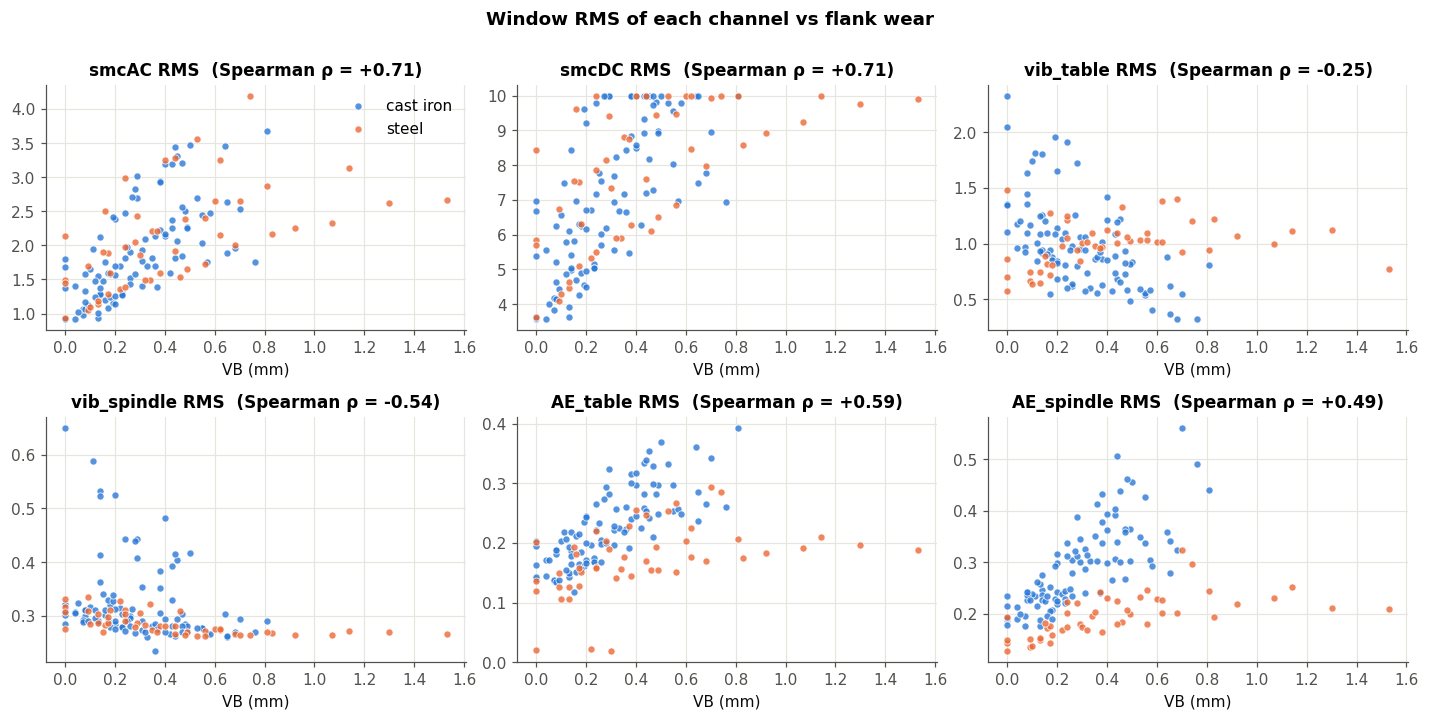

In [14]:
feat = features.merge(runs[["case", "run", "VB", "time", "valid", "material_name", "DOC", "feed"]], on=["case", "run"])
feat = feat[feat.valid]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.5))
for ax, s in zip(axes.flat, SIGNALS):
    col = f"{s}__rms"
    for mat in ["cast_iron", "steel"]:
        d = feat[(feat.material_name == mat) & feat.VB.notna()]
        ax.scatter(d.VB, d[col], s=22, color=MATERIAL_COLORS[mat], alpha=0.8, edgecolor="white", lw=0.6,
                   label=mat.replace("_", " "))
    rho = feat[[col, "VB"]].corr(method="spearman").iloc[0, 1]
    ax.set(title=f"{s} RMS  (Spearman ρ = {rho:+.2f})", xlabel="VB (mm)")
axes[0, 0].legend()
fig.suptitle("Window RMS of each channel vs flank wear", y=1.0, fontweight="semibold")
fig.tight_layout(); save(fig, "rms_vs_vb")

* **Spindle current (smcAC/smcDC)** rises with wear — a blunter edge needs more cutting force. smcDC
  hits the clipping ceiling (flat line at 10) for many worn runs, so smcAC is the cleaner force proxy.
* **AE** rises with wear for cast iron but stays flat for steel — a material-dependent relationship.
* **Vibration** RMS actually *decreases* with wear here and is dominated by case-to-case offsets.

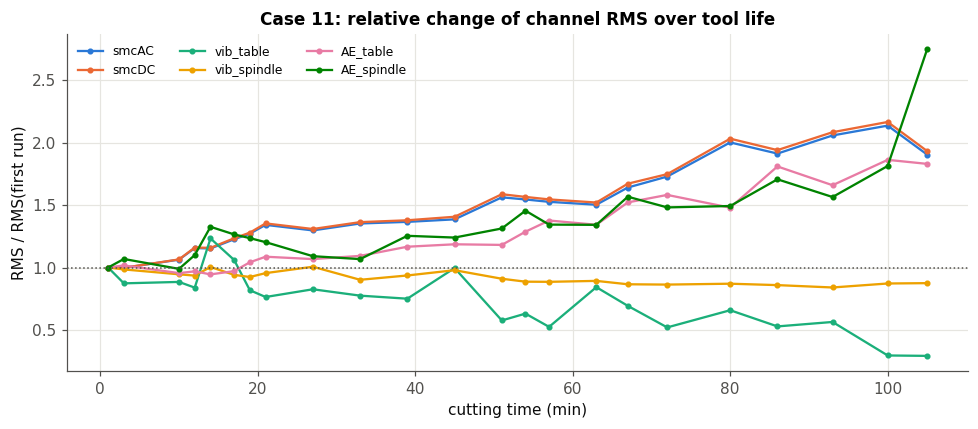

In [15]:
# Within one insert's life: channel RMS normalised to the first run, across runs of case 11.
c11 = feat[feat.case == 11].sort_values("time")
fig, ax = plt.subplots(figsize=(9, 4))
for k, s in enumerate(SIGNALS):
    v = c11[f"{s}__rms"].to_numpy()
    ax.plot(c11.time, v / v[0], "-o", ms=3, lw=1.5, color=PALETTE[k], label=s)
ax.axhline(1, color=INK_MUTED, lw=1, ls=":")
ax.set(xlabel="cutting time (min)", ylabel="RMS / RMS(first run)", title="Case 11: relative change of channel RMS over tool life")
ax.legend(ncol=3, fontsize=8); fig.tight_layout(); save(fig, "case11_rms_trend")

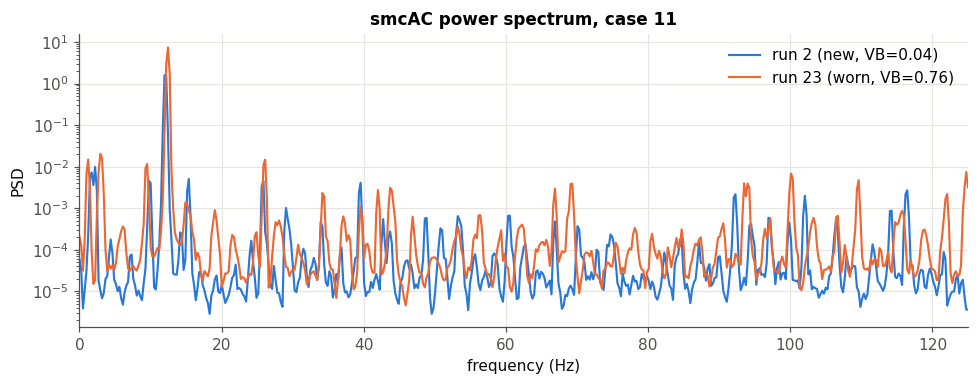

In [16]:
# Spectrum of the AC spindle current: new vs worn (case 11)
fig, ax = plt.subplots(figsize=(9, 3.6))
for k, (r, lbl) in enumerate([(2, "new"), (23, "worn")]):
    x = signals[pick(11, r), SIGNALS.index("smcAC"), WINDOW[0]:WINDOW[1]].astype(float)
    f, p = sps.welch(x - x.mean(), fs=FS, nperseg=1024)
    ax.semilogy(f, p, color=PALETTE[k], lw=1.4, label=f"run {r} ({lbl}, VB={runs.loc[pick(11, r), 'VB']})")
ax.set(xlabel="frequency (Hz)", ylabel="PSD", title="smcAC power spectrum, case 11", xlim=(0, FS / 2))
ax.legend(); fig.tight_layout(); save(fig, "smcAC_psd")

The AC current spectrum is dominated by one narrow line at ~12–13 Hz, close to the spindle rotation
frequency (826 rpm ≈ 13.8 Hz). With wear that line grows by ~an order of magnitude and shifts slightly,
while the rest of the spectrum changes little — **amplitude features carry most of the wear information**.

## 6. Feature relevance

In [17]:
fcols = [c for c in features.columns if "__" in c]
lab = feat[feat.VB.notna()]
rho_all = lab[fcols].corrwith(lab.VB, method="spearman")
rho_ci = lab[lab.material_name == "cast_iron"][fcols].corrwith(lab[lab.material_name == "cast_iron"].VB, method="spearman")
rho_st = lab[lab.material_name == "steel"][fcols].corrwith(lab[lab.material_name == "steel"].VB, method="spearman")
rel = pd.DataFrame({"all": rho_all, "cast_iron": rho_ci, "steel": rho_st}).dropna()
top = rel.reindex(rel["all"].abs().sort_values(ascending=False).index).head(20)
top

,all,cast_iron,steel
AE_spindle__band_60_100,0.726,0.788,0.640
smcAC__std,0.710,0.734,0.670
smcAC__rms,0.709,0.733,0.670
smcDC__p95,0.707,0.740,0.645
smcDC__rms,0.706,0.727,0.674
smcDC__mean,0.705,0.724,0.674
smcAC__p95,0.703,0.729,0.653
smcDC__max,0.699,0.729,0.643
smcAC__band_10_30,0.696,0.690,0.718
AE_table__band_60_100,0.686,0.763,0.541


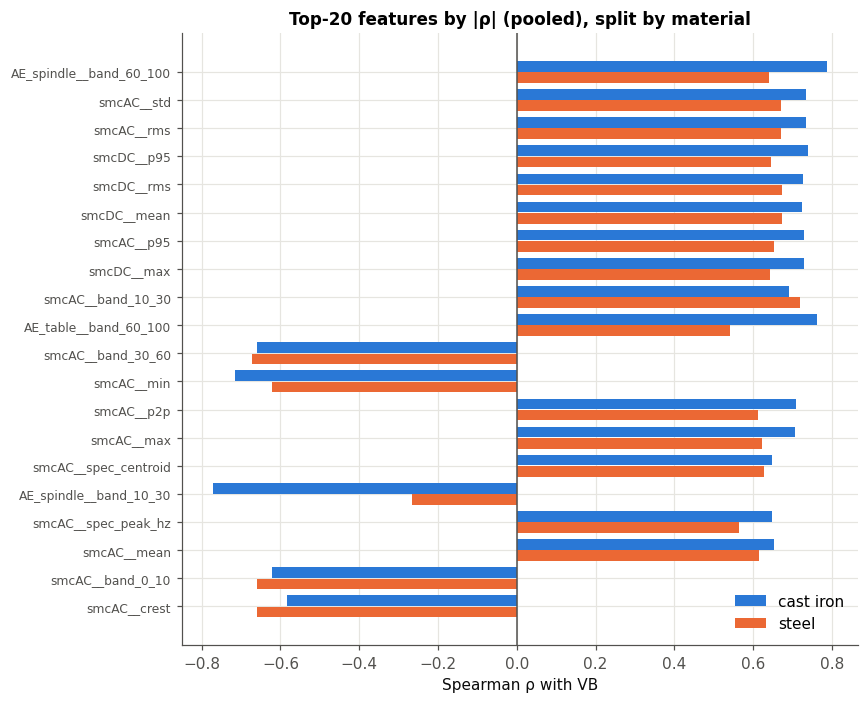

In [18]:
fig, ax = plt.subplots(figsize=(8, 6.5))
y = np.arange(len(top))[::-1]
ax.barh(y + 0.2, top["cast_iron"], height=0.38, color=MATERIAL_COLORS["cast_iron"], label="cast iron")
ax.barh(y - 0.2, top["steel"], height=0.38, color=MATERIAL_COLORS["steel"], label="steel")
ax.set_yticks(y, top.index, fontsize=8)
ax.axvline(0, color=INK_MUTED, lw=1)
ax.set(xlabel="Spearman ρ with VB", title="Top-20 features by |ρ| (pooled), split by material")
ax.legend(loc="lower right"); fig.tight_layout(); save(fig, "feature_corr")

Spindle-current features track VB similarly for both materials (ρ ≈ 0.6–0.7), while AE features are
strong for cast iron but much weaker for steel. The sensor→wear mapping depends on the process, so the
model should see the process parameters alongside the sensor features.

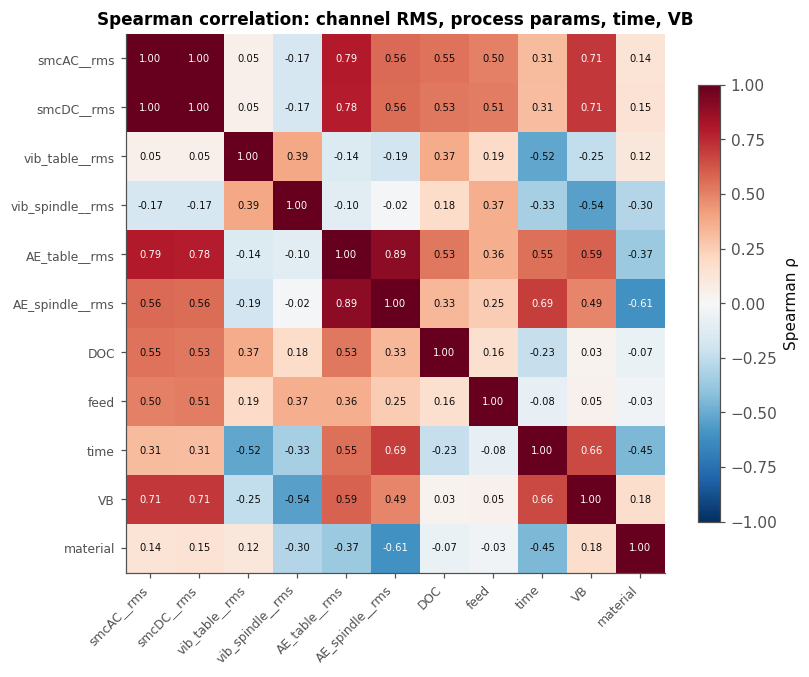

In [19]:
cols = [f"{s}__rms" for s in SIGNALS] + ["DOC", "feed", "time", "VB"]
lab2 = lab.assign(material=(lab.material_name == "steel").astype(int))
corr = lab2[cols + ["material"]].corr(method="spearman")
fig, ax = plt.subplots(figsize=(7.5, 6.2))
im = ax.imshow(corr, cmap="RdBu_r", vmin=-1, vmax=1)
ax.set_xticks(range(len(corr)), corr.columns, rotation=45, ha="right", fontsize=8)
ax.set_yticks(range(len(corr)), corr.columns, fontsize=8)
ax.grid(False)
for i in range(len(corr)):
    for j in range(len(corr)):
        ax.text(j, i, f"{corr.iloc[i, j]:.2f}", ha="center", va="center", fontsize=6.5,
                color="white" if abs(corr.iloc[i, j]) > 0.6 else "#0b0b0b")
fig.colorbar(im, ax=ax, shrink=0.8, label="Spearman ρ")
ax.set_title("Spearman correlation: channel RMS, process params, time, VB")
fig.tight_layout(); save(fig, "corr_heatmap")

## 7. Takeaways for modelling
See the summary in `README.md` → *EDA findings*. In short:
1. **145 usable labelled runs** from 15 informative inserts — a *small-data* problem; favour simple models and strict CV.
2. **Split by case** (leave-one-case-out): runs within a case are near-duplicates of each other.
3. Use the **steady-state window** only; handle the smcDC clipping (it's a real saturation, not a feature).
4. **Material** is the largest source of variance → include process parameters as inputs.
5. Cutting **time** alone is a strong (but not sensor-based) predictor — report it as a baseline so sensor models are judged honestly.